# 03 · Pipeline Observatory — detect data failures before users do

**Goal:** Define freshness, volume and failure-rate indicators and investigate alerts.

**Setup:** Synthetic measurements, standard-library Python and Matplotlib.

**CS bridge:** Monitoring, time semantics and false positives.

**Note:** This is a teaching scenario; real SLO thresholds depend on the product and its consumers.

## Watch and learn — Scheduling and backfills

[**Watch the original video on YouTube**](https://www.youtube.com/watch?v=1pu_C_oOAMA). Suggested: a 5–15 minute segment on a topic you need to revisit.

[![Video thumbnail](https://img.youtube.com/vi/1pu_C_oOAMA/hqdefault.jpg)](https://www.youtube.com/watch?v=1pu_C_oOAMA)

An embedded player may work in Jupyter with internet access. The video is optional; the learning exercises remain usable offline.

In [1]:
# Optional video player (does not download or store the video)
try:
    from IPython.display import display, YouTubeVideo
    display(YouTubeVideo("1pu_C_oOAMA", width=720, height=405))
except ImportError:
    print("Open the YouTube link in the Markdown above.")

**Supplementary reading/video:** [DataTalks.Club — Workflow Orchestration](https://github.com/DataTalksClub/data-engineering-zoomcamp/tree/main/02-workflow-orchestration). Focus on retries and monitoring, then return to this notebook and write a test.

## 1. Who notices the incident?

A dashboard is used for emergency coordination. Its data counts as fresh if the latest event arrived less than 60 minutes ago. Which alerts should fire when the upstream source stops publishing events?

In [2]:
from datetime import datetime,timedelta,timezone
from statistics import mean
runs=[
    {"hour":0,"freshness_min":9,"rows":55,"success":True},
    {"hour":1,"freshness_min":12,"rows":49,"success":True},
    {"hour":2,"freshness_min":17,"rows":51,"success":True},
    {"hour":3,"freshness_min":68,"rows":0,"success":False},
    {"hour":4,"freshness_min":87,"rows":0,"success":False},
    {"hour":5,"freshness_min":11,"rows":60,"success":True},
]
fail_rate=1-sum(r['success'] for r in runs)/len(runs)
mean_volume=mean(r['rows'] for r in runs)
alerts=[r['hour'] for r in runs if r['freshness_min']>60]
print('failure rate:',round(fail_rate,3),'mean volume:',round(mean_volume,1),'freshness alerts at hour:',alerts)
assert alerts==[3,4] and round(fail_rate,2)==0.33

failure rate: 0.333 mean volume: 35.8 freshness alerts at hour: [3, 4]


## 2. A chart that explains the incident

What is the difference between runner error rate and consumer-visible data freshness? How can the runner report `success=True` while the data product remains stale?

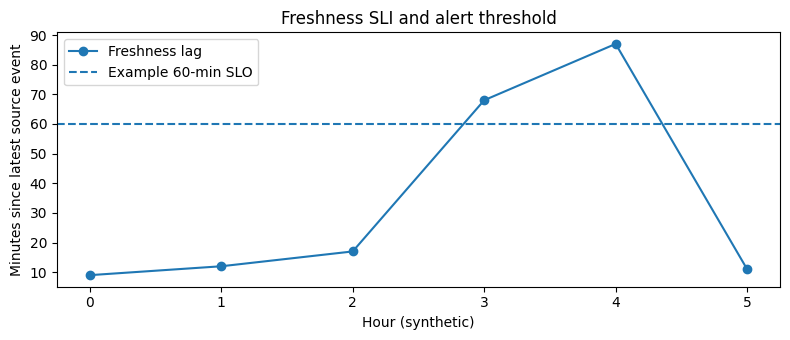

In [3]:
import matplotlib.pyplot as plt
hours=[r['hour'] for r in runs]
lag=[r['freshness_min'] for r in runs]
fig,ax=plt.subplots(figsize=(8,3.5))
ax.plot(hours,lag,marker='o',label='Freshness lag')
ax.axhline(60,ls='--',label='Example 60-min SLO')
ax.set(xlabel='Hour (synthetic)',ylabel='Minutes since latest source event',title='Freshness SLI and alert threshold')
ax.legend();plt.tight_layout();plt.show()

## 3. Failure injection and validation

- Add a successful run with `freshness_min=120`. What changes in the chart?
- Add an upstream source that is legitimately inactive. How will you avoid a false alarm while distinguishing it from a broken pipeline?
- Define an SLI for the fraction of hours with fresh data; identify the measurement window and denominator.
- Design escalation after a two-hour outage and a runbook for controlled replay.

**Next:** [Stage 07](../curriculum/modules/07.md) and [Stage 12](../curriculum/modules/12.md).